In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, balanced_accuracy_score

import joblib

In [12]:
df = pd.read_csv('collisions_merged_clean.csv')
df.head()

C:\Users\Morayo\AppData\Local\Temp\ipykernel_32464\2217919284.py:1: DtypeWarning: Columns (0: collision_index, 1: collision_ref_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('collisions_merged_clean.csv')


,collision_index,collision_ref_no,collision_severity,number_of_vehicles,number_of_casualties,day_of_week,first_road_class,first_road_number,road_type,speed_limit,...,num_vehicles_recorded,has_motorcycle,has_pedal_cycle,has_hgv,has_bus,max_driver_age,min_driver_age,any_skidding,num_left_hand_drive,any_escooter
0,202417H100324,17H100324,2,1,5,6,3,689,3.0,50.0,...,1.0,0.0,0.0,0.0,0.0,26.0,26.0,0.0,1.0,0.0
1,202417M110024,17M110024,3,2,1,2,6,0,6.0,30.0,...,2.0,0.0,1.0,0.0,0.0,35.0,35.0,0.0,2.0,0.0
2,2024480537342,480537342,3,1,2,4,3,201,6.0,20.0,...,1.0,0.0,1.0,0.0,0.0,33.0,33.0,1.0,1.0,0.0
3,202417M105824,17M105824,3,2,2,7,6,0,2.0,30.0,...,2.0,0.0,0.0,0.0,0.0,36.0,36.0,0.0,2.0,0.0
4,202417M114324,17M114324,3,1,1,6,3,66,3.0,50.0,...,1.0,1.0,0.0,0.0,0.0,19.0,19.0,0.0,1.0,0.0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100927 entries, 0 to 100926
Data columns (total 37 columns):
 #   Column                                       Non-Null Count   Dtype  
---  ------                                       --------------   -----  
 0   collision_index                              100927 non-null  object 
 1   collision_ref_no                             100927 non-null  object 
 2   collision_severity                           100927 non-null  int64  
 3   number_of_vehicles                           100927 non-null  int64  
 4   number_of_casualties                         100927 non-null  int64  
 5   day_of_week                                  100927 non-null  int64  
 6   first_road_class                             100927 non-null  int64  
 7   first_road_number                            100927 non-null  int64  
 8   road_type                                    98359 non-null   float64
 9   speed_limit                                  100924 non-null  float64


In [15]:
df.isnull().sum()
df['collision_severity'].value_counts(normalize=True) * 100

collision_severity
3    75.161255
2    23.350540
1     1.488204
Name: proportion, dtype: float64

In [6]:
df = df.drop(columns=['collision_index', 'collision_ref_no'])

In [7]:
y = df['collision_severity']
X = df.drop(columns=['collision_severity'])

In [8]:
X = X.fillna(X.median())

In [17]:
X_train, X_test, y_train, y_test = train_test_split (
    X,
    y,
    test_size=0.2,
    stratify = y,
    random_state=42
)

In [18]:
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [19]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (80741, 34)
Testing Data: (20186, 34)


In [20]:
model = RandomForestClassifier(
    n_estimators = 100,
    class_weight = 'balanced',
    random_state = 42
)

In [21]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [22]:
y_pred = model.predict(X_test)

In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.06      0.01      0.01       300
           2       0.36      0.39      0.37      4714
           3       0.80      0.80      0.80     15172

    accuracy                           0.69     20186
   macro avg       0.41      0.40      0.39     20186
weighted avg       0.69      0.69      0.69     20186



In [24]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))

Accuracy: 0.6891905280887743
Balanced Accuracy: 0.3963915479751789


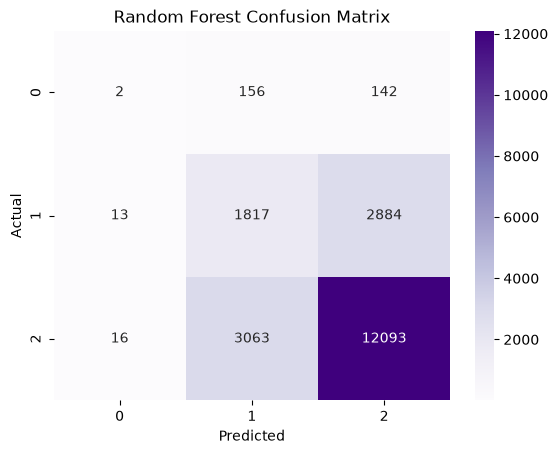

In [25]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')

plt.show()

In [26]:
model_50 = RandomForestClassifier(
    n_estimators=50,
    class_weight='balanced',
    random_state=42
)

model_50.fit(X_train, y_train)

pred_50 = model_50.predict(X_test)

print(classification_report(y_test, pred_50))

              precision    recall  f1-score   support

           1       0.11      0.01      0.02       300
           2       0.35      0.40      0.37      4714
           3       0.80      0.78      0.79     15172

    accuracy                           0.68     20186
   macro avg       0.42      0.40      0.40     20186
weighted avg       0.68      0.68      0.68     20186



In [27]:
model_100 = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

model_100.fit(X_train, y_train)

pred_100 = model_100.predict(X_test)

print(classification_report(y_test, pred_100))

              precision    recall  f1-score   support

           1       0.06      0.01      0.01       300
           2       0.36      0.39      0.37      4714
           3       0.80      0.80      0.80     15172

    accuracy                           0.69     20186
   macro avg       0.41      0.40      0.39     20186
weighted avg       0.69      0.69      0.69     20186



In [28]:
model_depth = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

model_depth.fit(X_train, y_train)

pred_depth = model_depth.predict(X_test)

print(classification_report(y_test, pred_depth))

              precision    recall  f1-score   support

           1       0.04      0.59      0.08       300
           2       0.31      0.43      0.36      4714
           3       0.85      0.55      0.67     15172

    accuracy                           0.52     20186
   macro avg       0.40      0.52      0.37     20186
weighted avg       0.71      0.52      0.59     20186



In [29]:
print("50 Trees:", balanced_accuracy_score(y_test, pred_50))

print("100 Trees:", balanced_accuracy_score(y_test, pred_100))

print("Max Depth 10:", balanced_accuracy_score(y_test, pred_depth))

50 Trees: 0.39725273039110204
100 Trees: 0.3963915479751789
Max Depth 10: 0.5228833950906521
